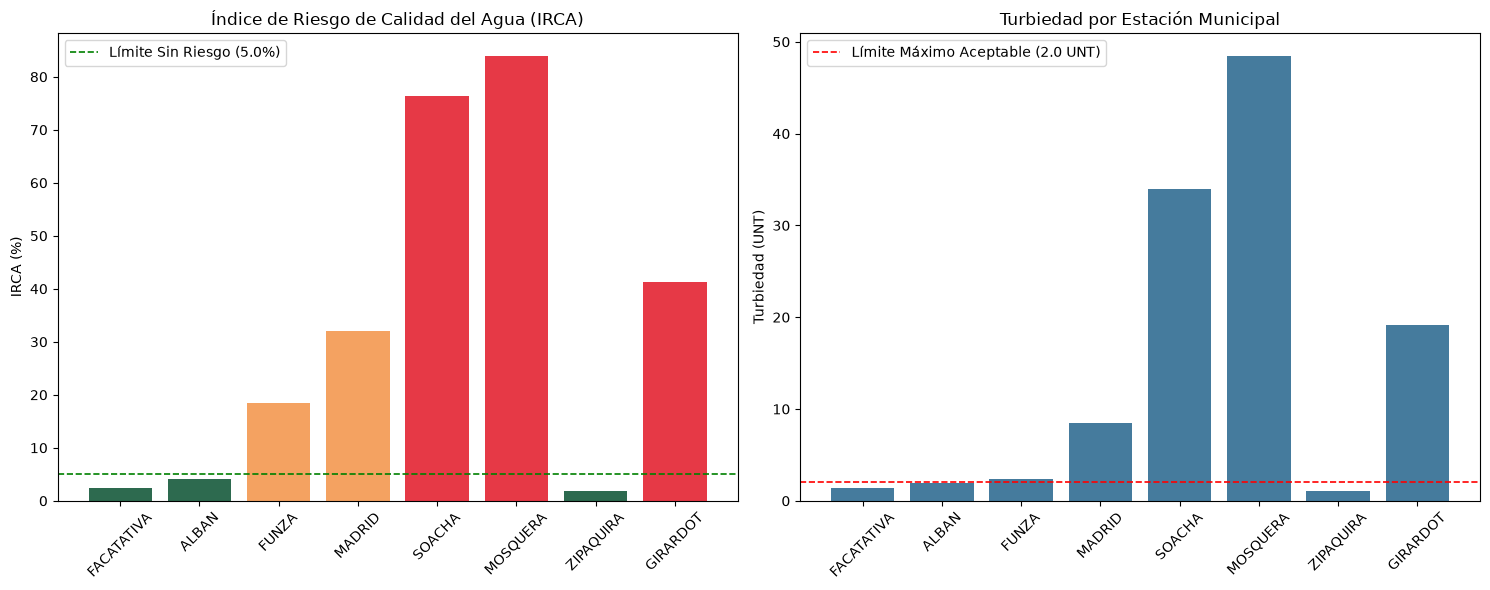

In [7]:

import csv
import matplotlib.pyplot as plt

# 1. Lectura de la base de datos
with open("notebooks/calidad_agua_cundinamarca_gov.csv",
          mode="r", encoding="utf-8") as f:
    datos = list(csv.DictReader(f))

municipios = [fila["municipio"] for fila in datos]
irca_valores = [float(fila["irca_porcentaje"]) for fila in datos]
turbiedad_valores = [float(fila["turbiedad_unt"]) for fila in datos]

# 2. Clasificación visual según niveles de riesgo
colores = []

for valor in irca_valores:
    if valor <= 5.0:
        colores.append("#2D6A4F")
    elif valor <= 35.0:
        colores.append("#F4A261")
    else:
        colores.append("#E63946")

# 3. Generación de gráficas comparativas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Gráfica de IRCA
ax1.bar(municipios, irca_valores, color=colores)
ax1.axhline(5.0, color="green", linestyle="--",
            linewidth=1.2, label="Límite Sin Riesgo (5.0%)")
ax1.set_title("Índice de Riesgo de Calidad del Agua (IRCA)")
ax1.set_ylabel("IRCA (%)")
ax1.tick_params(axis="x", rotation=45)
ax1.legend()

# Gráfica de turbiedad
ax2.bar(municipios, turbiedad_valores, color="#457B9D")
ax2.axhline(2.0, color="red", linestyle="--",
            linewidth=1.2, label="Límite Máximo Aceptable (2.0 UNT)")
ax2.set_title("Turbiedad por Estación Municipal")
ax2.set_ylabel("Turbiedad (UNT)")
ax2.tick_params(axis="x", rotation=45)
ax2.legend()

plt.tight_layout()
plt.show()
